# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# quick cleaning so variables and cleaned versions can be used here
import pandas as pd
import matplotlib.pyplot as plt

# Load transaction data
transactions = pd.read_csv("walmart_transactions.csv")

# Cleaning function
def clean_transactions(df):
    out = df.drop_duplicates().copy()

    # Clean unit prices
    out['unit_price'] = (
        out['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    # Parse timestamps
    out['timestamp'] = pd.to_datetime(
        out['timestamp'],
        errors='coerce',
        format='mixed'
    )

    # Standardize store IDs
    out['store_id'] = (
        out['store_id']
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    # Standardize category formatting
    out['category'] = (
        out['category']
        .str.strip()
        .str.title()
    )
    # Consolidate equivalent category names
    category_map = {
      'Alcohol': 'Alcoholic Beverages',
      'Baby': 'Baby Products',
      'Breakfast': 'Breakfast Foods',
      'Emergency': 'Emergency Supplies',
      'Games & Entertainment': 'Entertainment',
      'Grocery': 'Groceries',
      'Health': 'Health & Wellness',
      'Household': 'Household Essentials'
  }

    out['category'] = out['category'].replace(category_map)

    return out


cleaned = clean_transactions(transactions)

# Keep usable rows for gross demand analysis
q1 = cleaned[
    cleaned['timestamp'].notna() &
    (cleaned['quantity'] > 0)
].copy()

q1['date'] = q1['timestamp'].dt.normalize()

# Find the five categories with the most total units
top_categories = (
    q1.groupby('category')['quantity']
    .sum()
    .nlargest(5)
    .index
)

# Daily units sold for those categories
daily = (
    q1[q1['category'].isin(top_categories)]
    .groupby(['date', 'category'])['quantity']
    .sum()
    .unstack(fill_value=0)
)

landfall = pd.Timestamp('2024-09-26')

In [3]:
# TODO 1:
# Calculate the pre-storm baseline for each category
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()

# Divide each day's sales by that category's baseline
indexed = daily / baseline

# Show the highest surge multiple for each category
print("Peak multiple of baseline:")
print(indexed.max().round(1).sort_values(ascending=False))

# Surge window average
surge_window = daily[(daily.index >= landfall-pd.Timedelta(days=3)) & (daily.index < landfall)].mean()
surge_multiple = surge_window/baseline

Peak multiple of baseline:
category
Breakfast Foods         5.6
Emergency Supplies      3.4
Entertainment           2.9
Household Essentials    2.7
Groceries               2.1
dtype: float64


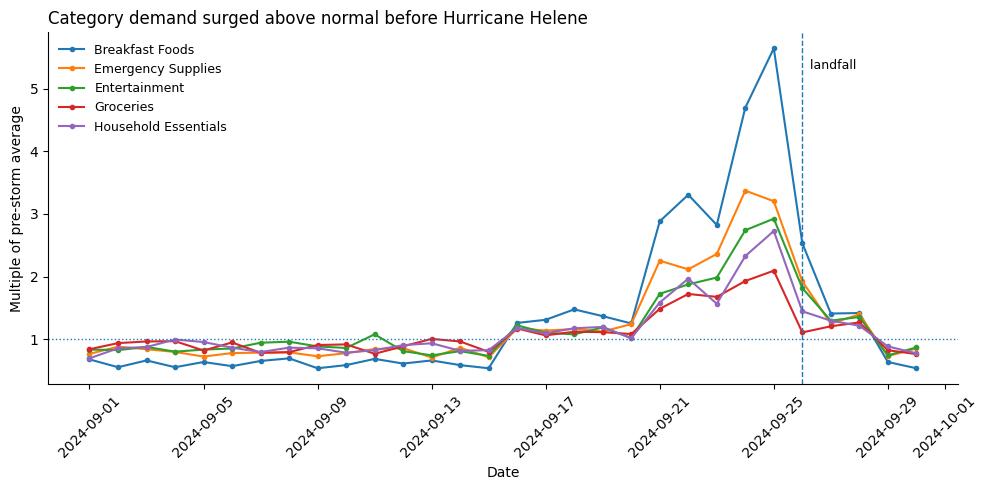

In [5]:
# TODO 2
# Plot each category as a multiple of normal demand
fig, ax = plt.subplots(figsize=(10, 5))

for col in indexed.columns:
    ax.plot(
        indexed.index,
        indexed[col],
        marker='o',
        markersize=3,
        label=col
    )

# Normal demand = 1.0
ax.axhline(
    1.0,
    linestyle=':',
    linewidth=1
)

# Hurricane Helene landfall
ax.axvline(
    landfall,
    linestyle='--',
    linewidth=1
)

ax.annotate(
    '  landfall',
    xy=(landfall, ax.get_ylim()[1] * 0.9),
    fontsize=9
)

ax.set_title(
    'Category demand surged above normal before Hurricane Helene',
    loc='left',
    fontsize=12
)

ax.set_xlabel('Date')
ax.set_ylabel('Multiple of pre-storm average')

ax.legend(frameon=False, fontsize=9)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** _..._

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

catalog shape:


(45, 7)


Distinct SKUs:
45

Product names:


,sku,product_name
0,PT-12,pop-tarts strawberry
1,SKU#459812,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry
4,WTR-24,BOTTLED WATER 24PK
5,WATER24PK,Bottled Water 24-Pack
6,WTR_24PK,Water - 24 Pack
7,BATT-100,BATTERIES AA 4PK
8,BAT-AA4,AA Batteries 4-Pack
9,BATT_AA_4PK,AA Batteries 4-Pack


,name_key,sku,product_name
12,24 beer light pack,BEER-24,Light Beer (24-pack)
13,24 beer light pack,LTBEER24,Light Beer (24-pack)
8,4 aa batteries pack,BAT-AA4,AA Batteries 4-Pack
9,4 aa batteries pack,BATT_AA_4PK,AA Batteries 4-Pack
30,aid first kit,FIRSTAID-KIT,First Aid Kit
29,aid first kit,FAID-01,First-Aid Kit
15,board game monopoly,MONOPOLY-01,Monopoly Board Game
14,board game monopoly,BG-MONO,Monopoly Board Game
16,board game monopoly,GAME-MONO,Board Game - Monopoly
24,bread white,WHITEBREAD,WHITE BREAD


Starting distinct SKUs: 45
Canonical products: 26

Largest groups:


,0
canonical_sku,
POPTART-STRAW,4
BAT-AA4,3
MONOPOLY-01,3
WTR-24,3
CANDLE-EMRG,2


,sku,product_name,canonical_sku
9,BATT_AA_4PK,AA Batteries 4-Pack,BAT-AA4
8,BAT-AA4,AA Batteries 4-Pack,BAT-AA4
7,BATT-100,BATTERIES AA 4PK,BAT-AA4
13,LTBEER24,Light Beer (24-pack),BEER-24
12,BEER-24,Light Beer (24-pack),BEER-24
24,WHITEBREAD,WHITE BREAD,BREAD-WH
23,BREAD-WH,WHITE BREAD,BREAD-WH
27,CNDL-EM,Candles (Emergency),CANDLE-EMRG
28,CANDLE-EMRG,Emergency Candles,CANDLE-EMRG
18,PLAYCARD-STD,PLAYING CARDS,CARDS-01


Units by original SKU:
sku
PT-12            1381
SKU#459812       1255
POPTART-STRAW    1300
PT_STRAWBERRY    1262
Name: quantity, dtype: int64

Consolidated Pop-Tarts units: 5198
Largest individual SKU: 1381
Consolidated total is 3.76 times the largest individual SKU


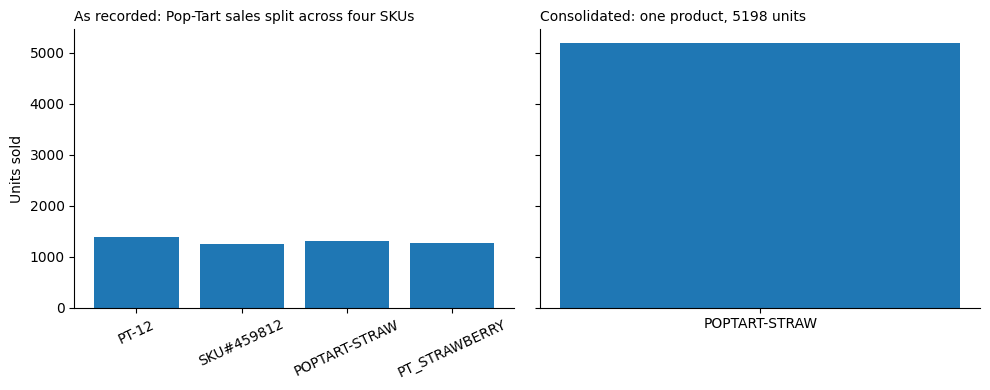

In [8]:
catalog = pd.read_csv("product_catalog.csv")

# inspect the dataset
print("catalog shape:")
display(catalog.shape)
print('\nDistinct SKUs:')
print(catalog['sku'].nunique())

print('\nProduct names:')
display(catalog[['sku','product_name']])

# first standardize all names to get a sense of which names mean the same thing
candidates = catalog.copy()
candidates['name_key'] = (candidates['product_name'].str.lower().str.replace(r'[^a-z0-9\s]',' ',regex=True).str.split().apply(lambda words: ' '.join(sorted(words))))
fragmented = candidates.groupby('name_key').filter(lambda group: group['sku'].nunique() >1)
display(fragmented[['name_key','sku','product_name']].sort_values('name_key'))

# combine same products with different SKUs by mapping
CANON = {
    # poptarts
    'PT-12':'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'POPTART-STRAW': 'POPTART-STRAW',
    'PT_STRAWBERRY':'POPTART-STRAW',

    # water
    'WTR-24': 'WTR-24',
    'WATER24PK':'WTR-24',
    'WTR_24PK': 'WTR-24',

    # batteries
    'BATT-100': 'BAT-AA4',
    'BAT-AA4': 'BAT-AA4',
    'BATT_AA_4PK': 'BAT-AA4',

    # flashlight
    'FLASH-01':'FLASH-01',
    'LED-FLASH':'FLASH-01',

    # beer
    'BEER-24':'BEER-24',
    'LTBEER24': 'BEER-24',

    # monopoly
    'BG-MONO':'MONOPOLY-01',
    'MONOPOLY-01':'MONOPOLY-01',
    'GAME-MONO':'MONOPOLY-01',

    # cards
    'CARDS-01':'CARDS-01',
    'PLAYCARD-STD':'CARDS-01',

    # canned soup
    'SOUP-CAN':'SOUP-CAN',
    'CNSOUP-01':'SOUP-CAN',

    # white bread
    'BREAD-WH':'BREAD-WH',
    'WHITEBREAD':'BREAD-WH',

    # peanut butter
    'PB-16':'PB-16',
    'PNUTBTR-16':'PB-16',

    # Emergency candles
    'CNDL-EM':'CANDLE-EMRG',
    'CANDLE-EMRG':'CANDLE-EMRG',

    # first aid kit
    'FAID-01':'FIRSTAID-KIT',
    'FIRSTAID-KIT':'FIRSTAID-KIT',

    # Paper towels
    'PTOWEL-6':'PTOWEL-6',
    'PAPERTOWEL6':'PTOWEL-6',

    # heavy duty tarp
    'TARP-HD':'TARP-HD',
    'HDTARP-01':'TARP-HD'
}

# apply it
catalog_clean = catalog.copy()
catalog_clean['canonical_sku'] = (catalog_clean['sku'].map(CANON).fillna(catalog_clean['sku']))

# check results
print("Starting distinct SKUs:", catalog['sku'].nunique())
print("Canonical products:", catalog_clean['canonical_sku'].nunique())

group_sizes = (catalog_clean.groupby('canonical_sku').size().sort_values(ascending=False))
print("\nLargest groups:")
display(group_sizes.head())

# show mapping
display(catalog_clean[catalog_clean['sku'].isin(CANON)][['sku','product_name','canonical_sku']].sort_values('canonical_sku'))


# Largest consolidated family: Strawberry Pop-Tarts
poptart_skus = [
    'PT-12',
    'SKU#459812',
    'POPTART-STRAW',
    'PT_STRAWBERRY'
]

# Total positive units sold under each separate SKU
fragmented = (
    cleaned[
        cleaned['sku'].isin(poptart_skus) &
        (cleaned['quantity'] > 0)
    ]
    .groupby('sku')['quantity']
    .sum()
    .reindex(poptart_skus)
    .fillna(0)
)

# Total after treating all four SKUs as one product
consolidated_units = fragmented.sum()

# Compare consolidated total with the largest individual SKU
largest_single_sku = fragmented.max()
multiple = consolidated_units / largest_single_sku

print("Units by original SKU:")
print(fragmented)

print("\nConsolidated Pop-Tarts units:", consolidated_units)
print("Largest individual SKU:", largest_single_sku)
print("Consolidated total is", round(multiple, 2), "times the largest individual SKU")

# Before-and-after chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].bar(
    fragmented.index,
    fragmented.values
)

axes[0].set_title(
    'As recorded: Pop-Tart sales split across four SKUs',
    fontsize=10,
    loc='left'
)

axes[0].tick_params(
    axis='x',
    labelrotation=25
)

axes[1].bar(
    ['POPTART-STRAW'],
    [consolidated_units]
)

axes[1].set_title(
    f'Consolidated: one product, {int(consolidated_units)} units',
    fontsize=10,
    loc='left'
)

axes[0].set_ylabel('Units sold')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Assertion proving consolidation did not change unit totals
consolidated = cleaned.copy()
consolidated['canonical_sku'] = (consolidated['sku'].map(CANON).fillna(consolidated['sku']))
before_total = cleaned['quantity'].sum()
after_total = consolidated['quantity'].sum()
assert before_total == after_total

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [9]:
import requests
import time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()

            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()

        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'

        return frame

weather = daily_weather(
    '2024-09-01',
    '2024-09-30'
)

display(weather.head())
print("Weather rows:", len(weather))

# STILL NEED FOR Q3:
# join the daily sales data with the weather data
# print the row count before and after the join to prove no days were lost
# calculate the correlation between sales and the weather variables
# report whether the weather data is live or fallback
# report how many days are included in the correlation

,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo


Weather rows: 30


**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_